In [3]:
from pathlib import Path

Path("41586_2022_4492_MOESM4_ESM.xlsx").is_file()

True

In [4]:
import polars as pl

data_frame = pl.read_excel(
    "41586_2022_4492_MOESM4_ESM.xlsx",
    sheet_name="B",
)
data_frame

Edge_cog,Network_cog,Component_cog,Edge_psy,Network_psy,Component_psy
f64,f64,f64,f64,f64,f64
0.015811,0.049909,0.134635,-0.013585,-0.051539,-0.040068
0.072277,-0.023721,-0.04805,-0.022768,0.001613,-0.025
-0.012047,0.06388,-0.065145,-0.01468,-0.011645,0.036824
0.038204,-0.025794,-0.08812,-0.014388,0.037186,0.059933
0.0048823,-0.008084,0.055477,0.0064374,0.021742,-0.039472
…,…,…,…,…,…
-0.0192,null,null,-0.003152,null,null
-0.005679,null,null,-0.007033,null,null
0.0064225,null,null,0.034054,null,null


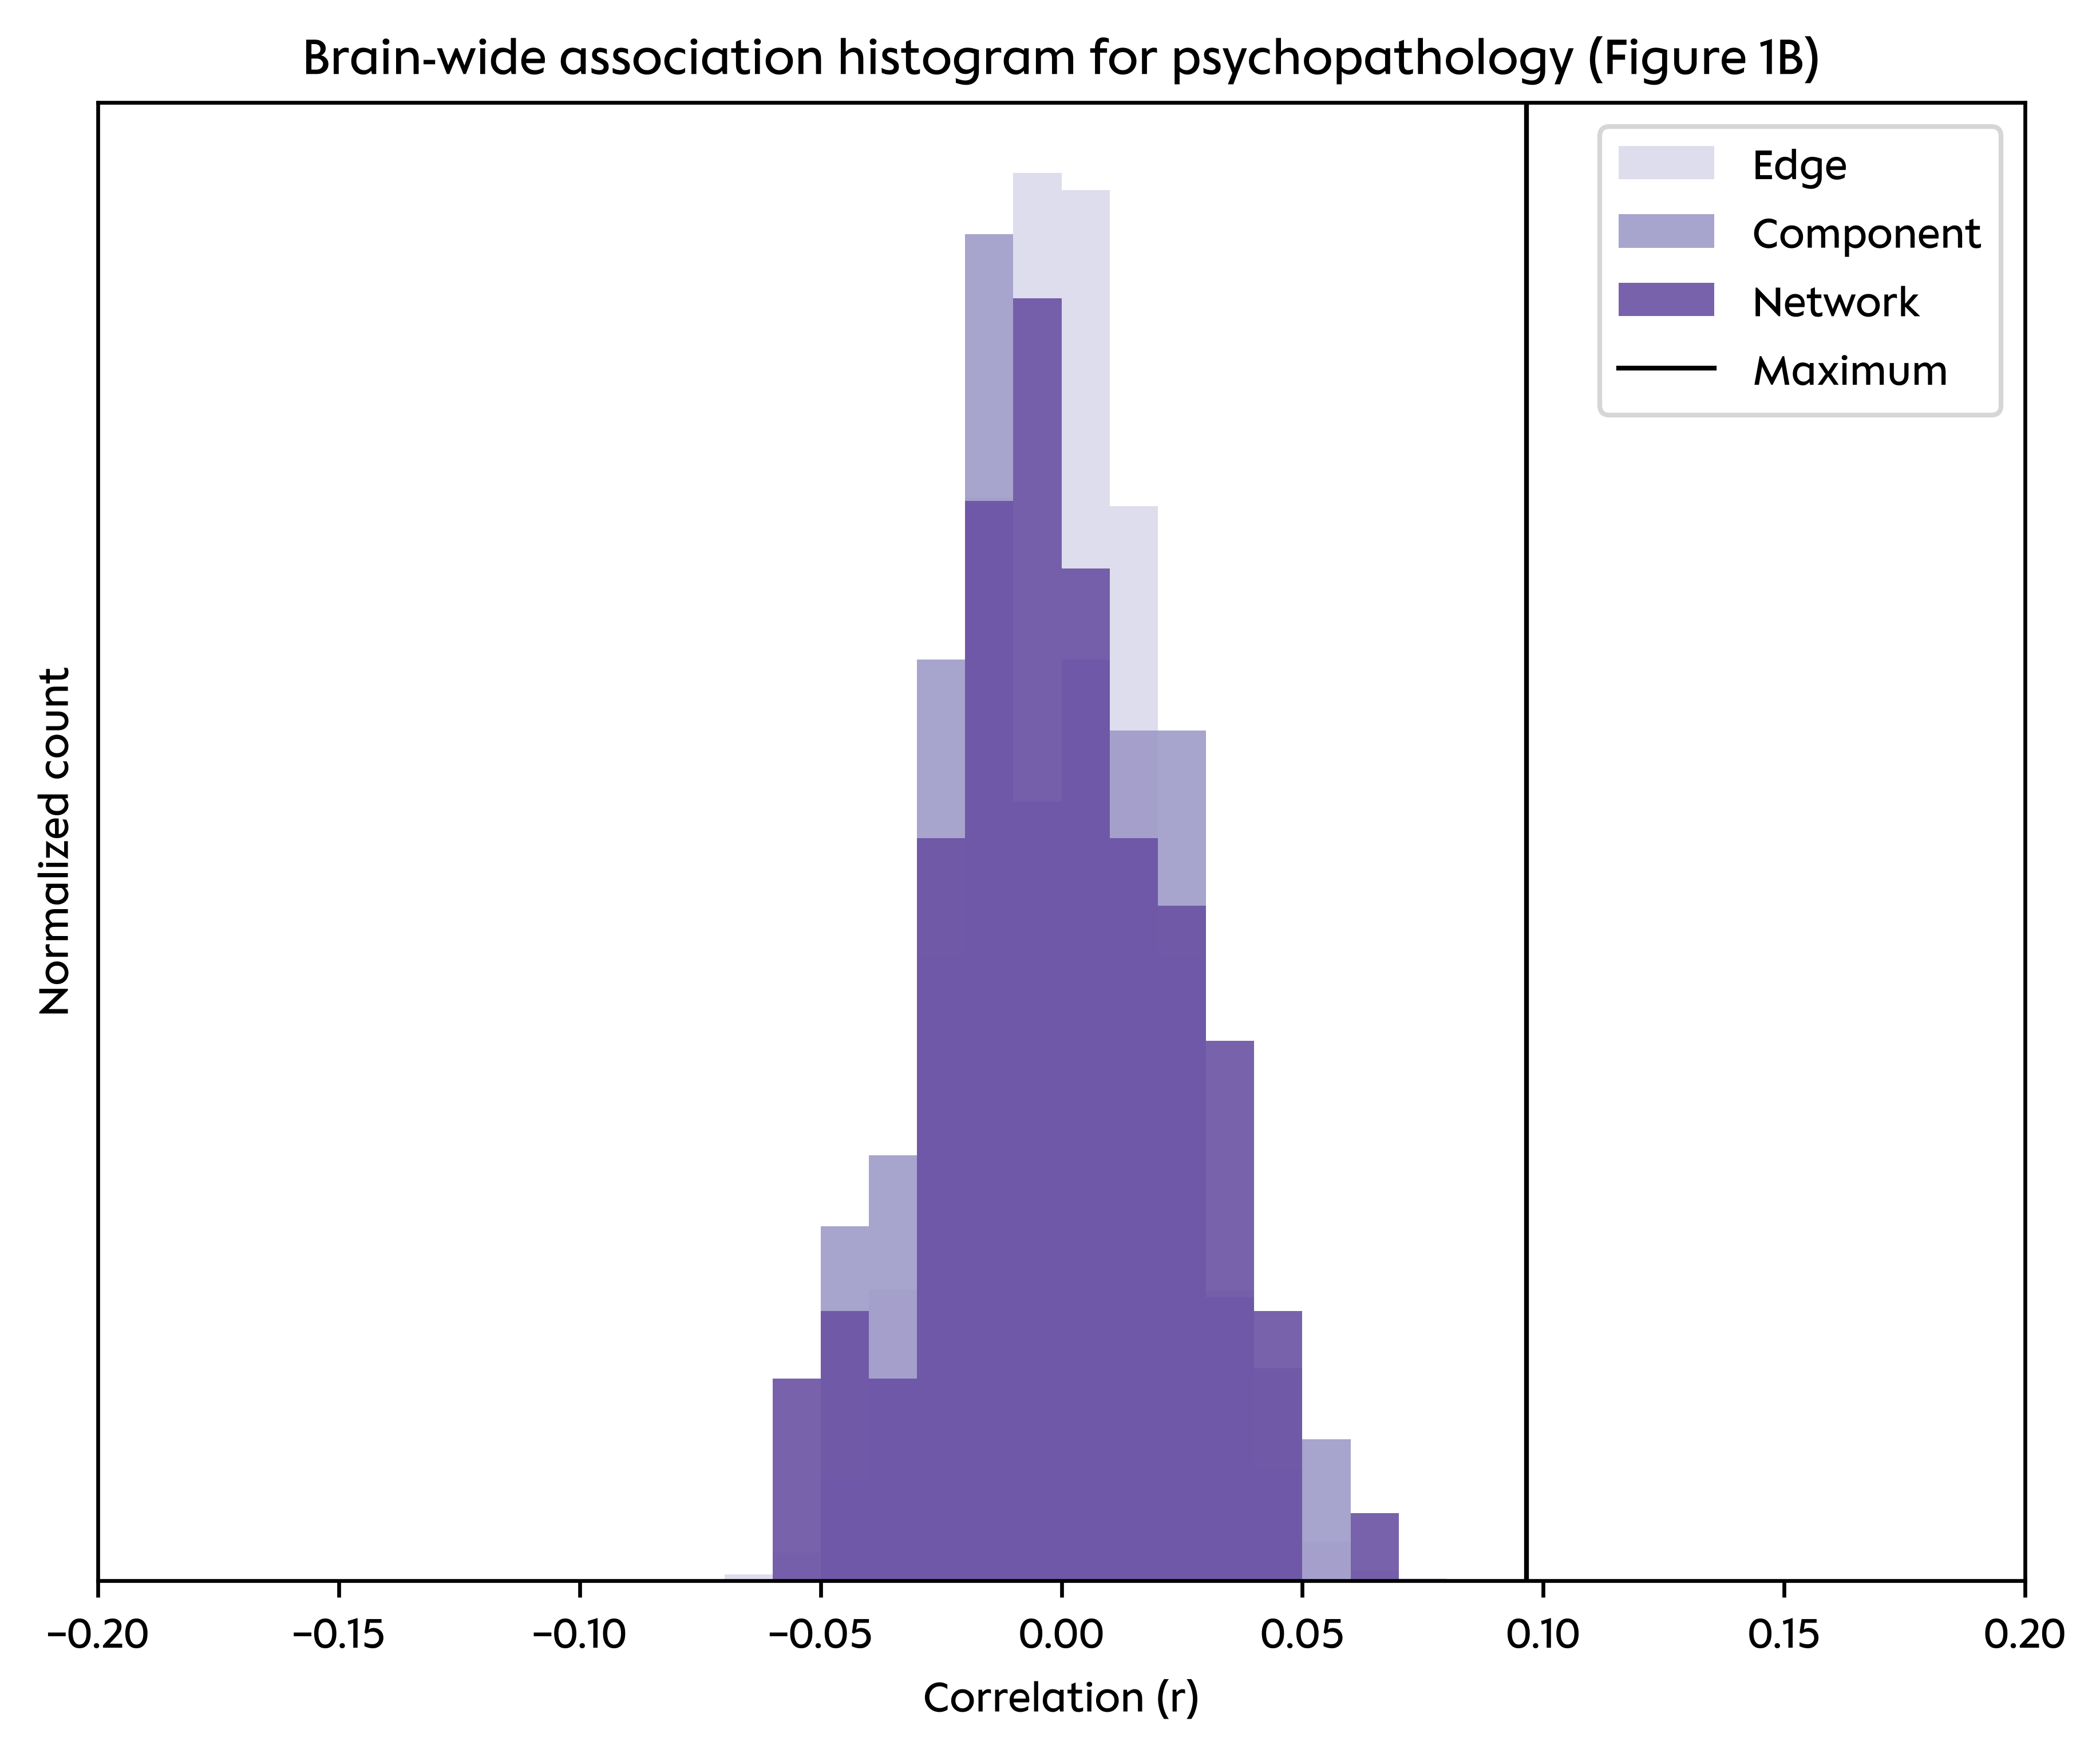

In [5]:
import numpy as np
from matplotlib import pyplot as plt

font_family = "Charité Text Office"
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": [f"{font_family}"],
        "mathtext.fontset": "custom",
        "mathtext.rm": f"{font_family}",
        "mathtext.it": f"{font_family}:italic",
        "mathtext.bf": f"{font_family}:bold",
        "mathtext.bfit": f"{font_family}:bold:italic",
        "mathtext.sf": f"{font_family}",
    }
)

figure, axes = plt.subplots(
    nrows=1, ncols=1, figsize=(6, 5), dpi=600, constrained_layout=True
)

edge = data_frame.get_column("Edge_psy").drop_nulls().to_numpy()
network = data_frame.get_column("Network_psy").drop_nulls().to_numpy()
component = data_frame.get_column("Component_psy").drop_nulls().to_numpy()

arrays = [network, component, edge]
handles = axes.hist(
    arrays,
    bins=(np.arange(-20.0, 21.0) / 100).tolist(),
    weights=[np.full(len(array), 1 / len(array)) for array in arrays],
    histtype="stepfilled",
    alpha=0.9,
    color=["#6a51a3", "#9e9ac8", "#dadaeb"],
    label=["Network", "Component", "Edge"],
)

axes.set_xlim(-0.2, 0.2)
axes.set_xlabel("Correlation (r)")
axes.set_yticks([])
axes.set_ylabel("Normalized count")

axes.axvline(
    x=max(max(edge), max(network), max(component)),
    linestyle="-",
    linewidth=1.0,
    color="#000000",
    label="Maximum",
)
axes.legend()
# axes.annotate(
#     "Maximum", xy=(0.0946964348164375, 0.0), xytext=(0.1, 0.005), color="#000000"
# )

axes.set_title(
    "Brain-wide association histogram for psychopathology (Figure 1B)",
)

figure.savefig(
    "marek-2022-figure-1-b-right.png",
    dpi=600,
    bbox_inches="tight",
)

In [6]:
array = pl.read_excel(
    "41586_2022_4492_MOESM4_ESM.xlsx",
    sheet_name="F_right",
    has_header=False,
    columns=range(16),
).to_numpy()
array.shape, array[:, -1].mean()

((1000, 16), np.float64(0.097079734))

In [7]:
x = np.array(
    [
        25,
        33,
        50,
        70,
        100,
        135,
        200,
        265,
        375,
        525,
        725,
        1_000,
        1_430,
        2_000,
        2_800,
        3_928,
    ]
)
len(x)

16

In [8]:
import scipy.stats

t = scipy.stats.t.ppf(1 - 0.05 / 2, df=x - 2)
critical_r = t / np.sqrt(x - 2 + t**2)
critical_r

array([0.39606973, 0.34395729, 0.27871059, 0.23519784, 0.1965512 ,
       0.16904273, 0.13878885, 0.12053012, 0.10128982, 0.08558683,
       0.07282023, 0.06199742, 0.05184035, 0.04383247, 0.03704367,
       0.03127479])

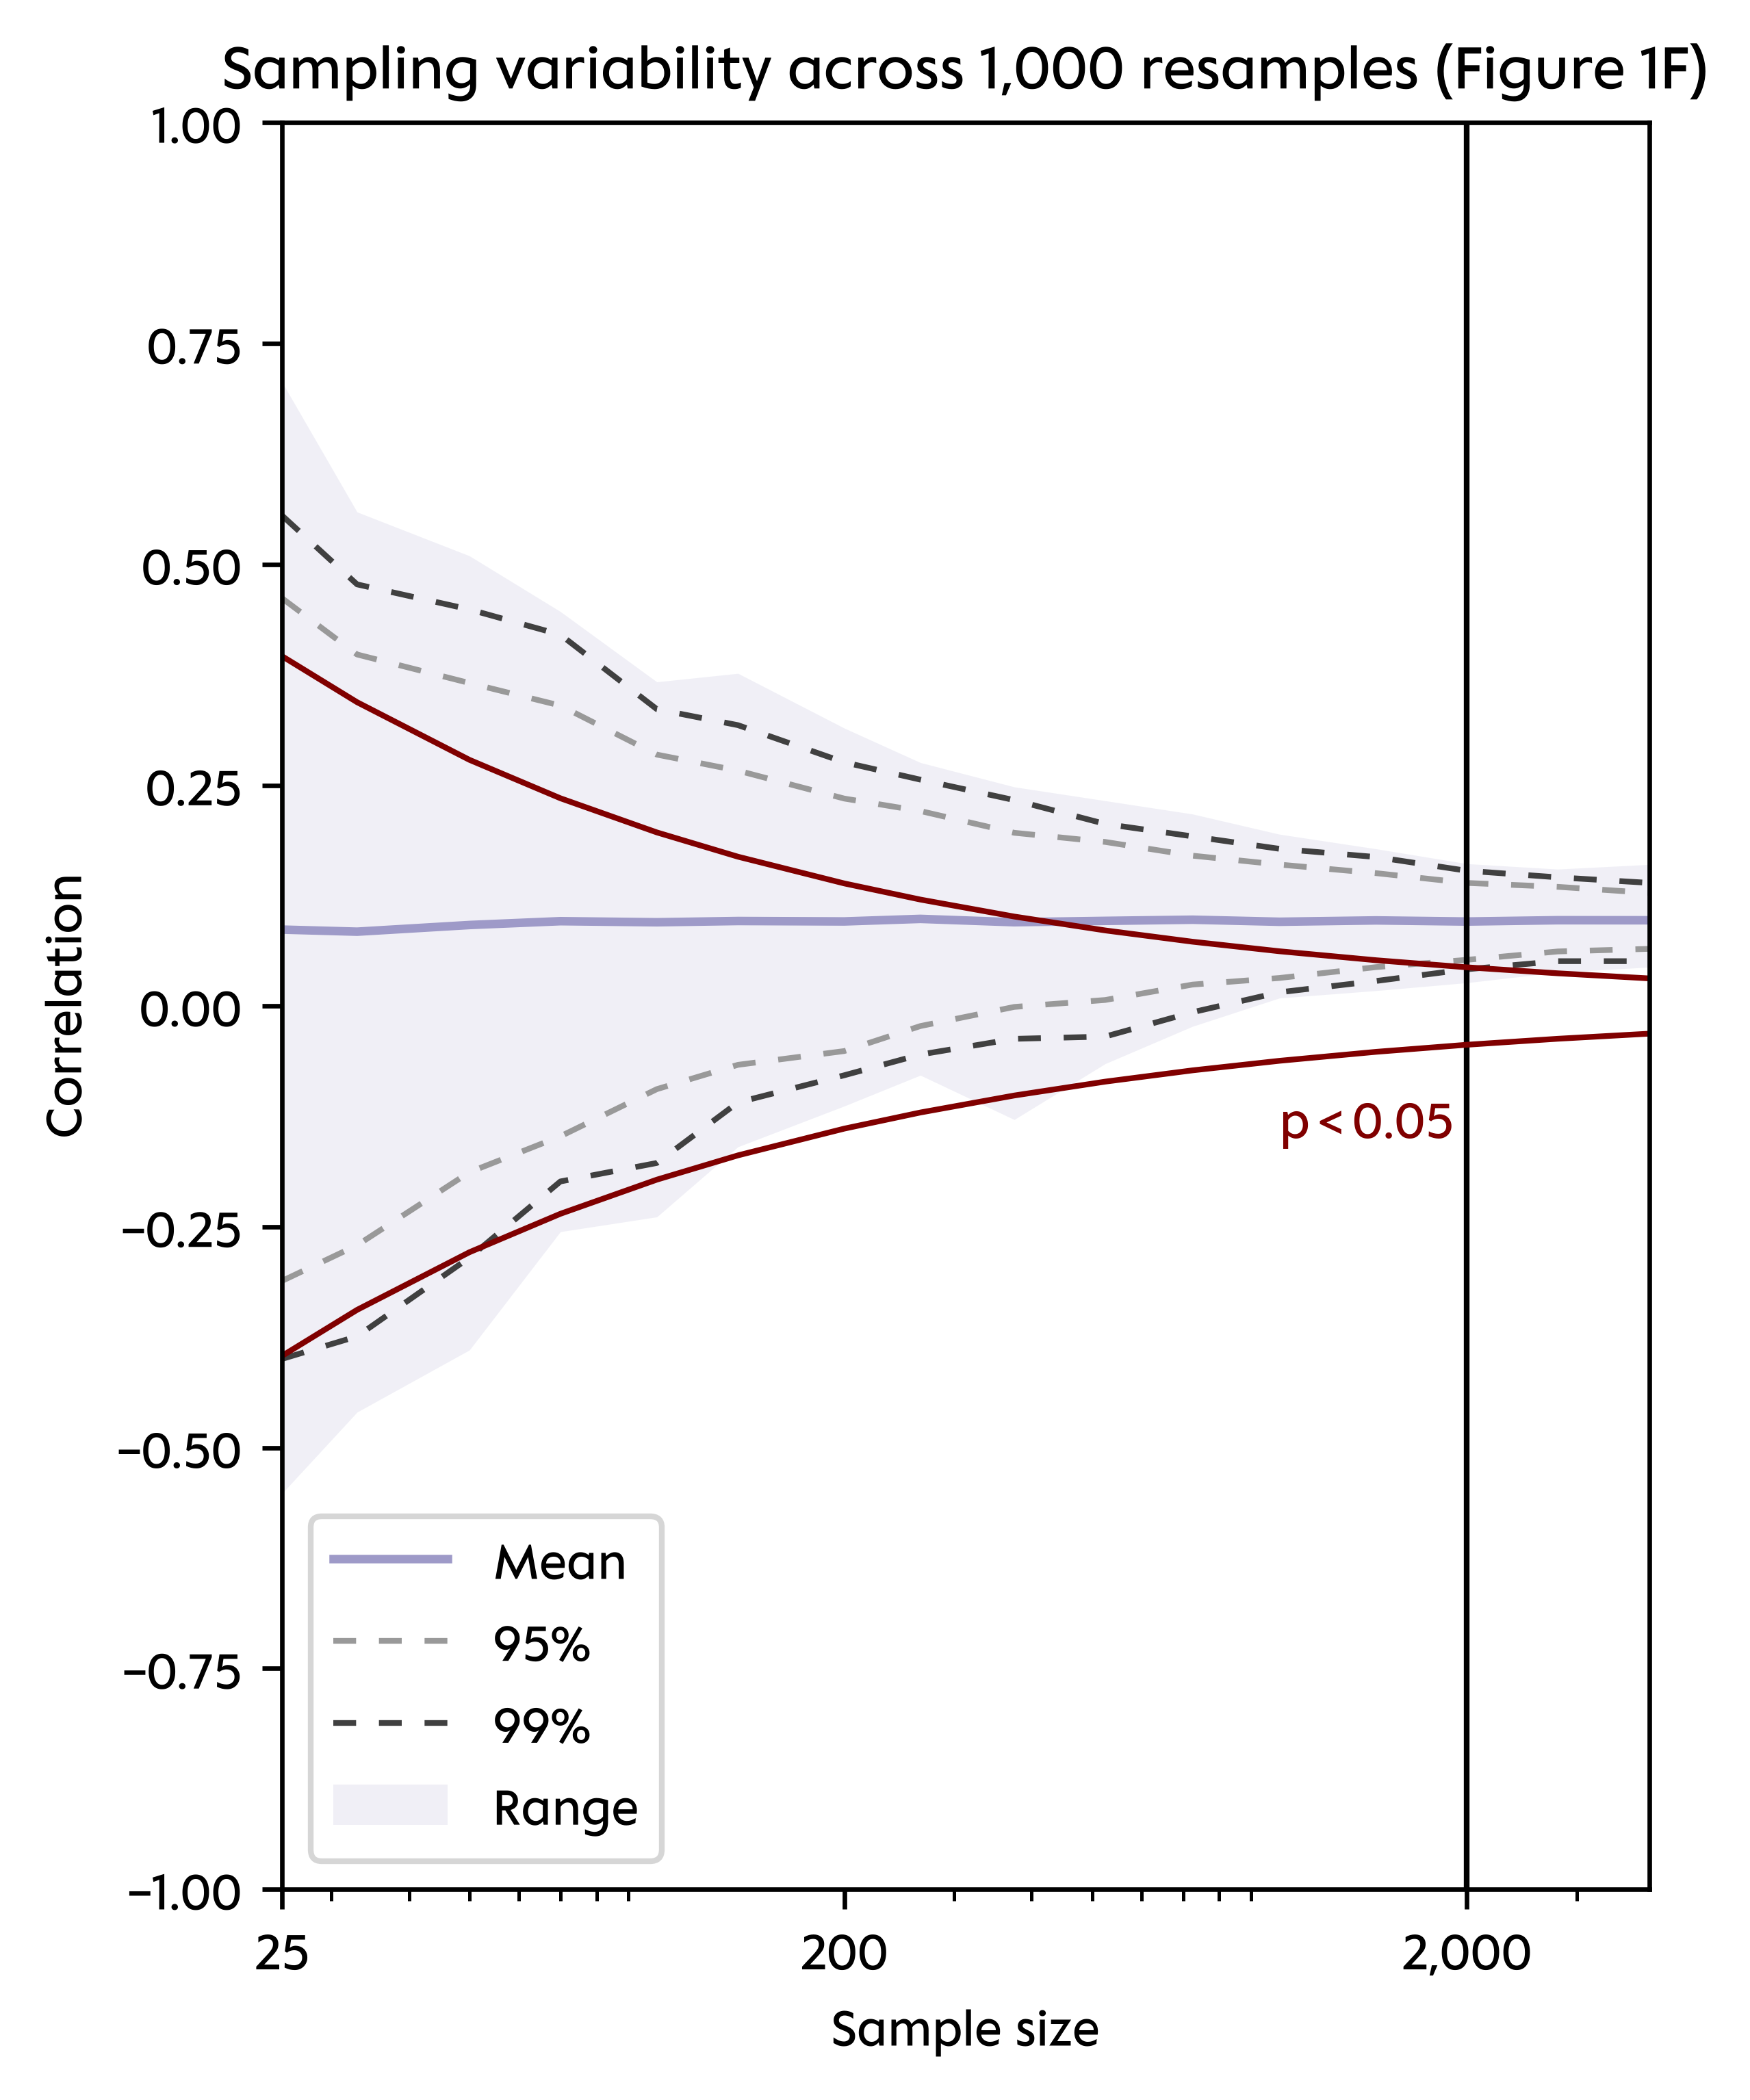

In [9]:
figure, axes = plt.subplots(
    nrows=1, ncols=1, figsize=(4, 5), dpi=600, constrained_layout=True
)

axes.plot(
    x,
    array.mean(axis=0),
    color="#9e9ac8",
    label="Mean",
)

axes.plot(
    x,
    np.percentile(array, [2.5, 97.5], axis=0).transpose(),
    "--",
    color="0.6",
    lw=1,
    dashes=(4, 4),
    label=["95%", "_nolegend_"],
)
axes.plot(
    x,
    np.percentile(array, [0.5, 99.5], axis=0).transpose(),
    "--",
    color="0.25",
    lw=1,
    dashes=(4, 4),
    label=["99%", "_nolegend_"],
)

axes.fill_between(
    x,
    array.min(axis=0),
    array.max(axis=0),
    color="#9e9ac8",
    alpha=0.15,
    lw=0,
    label="Range",
)

axes.legend()

axes.axvline(x=2_000, linestyle="-", linewidth=1.0, color="#000000")

axes.plot(x, critical_r, "-", color="maroon", lw=1)
axes.plot(x, -critical_r, "-", color="maroon", lw=1)
axes.annotate("$p < 0.05$", xy=(1_000, -0.2), xytext=(1_000, -0.15), color="maroon")

axes.set_xscale("log")
axes.set_xlim(min(x), max(x))
axes.set_xticks([25, 200, 2_000], labels=["25", "200", "2,000"])
axes.set_ylim(-1.0, 1.0)

axes.set_xlabel("Sample size")
axes.set_ylabel("Correlation")

axes.set_title(
    "Sampling variability across 1,000 resamples (Figure 1F)",
)

figure.savefig(
    "marek-2022-figure-1-f-right.svg",
    bbox_inches="tight",
    pad_inches=0,
    transparent=True,
)